https://arxiv.org/abs/1502.03167

In [2]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch.nn.functional as F
torch.manual_seed(42);

In [2]:
%%capture
! [ -f names.txt ] || wget https://raw.githubusercontent.com/karpathy/makemore/refs/heads/master/names.txt

In [3]:
df = pd.read_csv("names.txt", header=None)
names = df[0].str.lower()

In [4]:
blocks = 3
X, Y = [], []

for name in names:
	context = [0] * blocks
	for c in name:
		idx = ord(c) - ord("a")
		X.append(context)
		Y.append(idx)
		context = context[1:] + [idx]
	X.append(context)
	Y.append(26)

X = torch.tensor(X)
Y = torch.tensor(Y)

N = len(names)
Ntrain = N * 8 // 10

Xtrain, Ytrain = X[:Ntrain], Y[:Ntrain]
Xval, Yval = X[Ntrain:], Y[Ntrain:]

Activation: Ideal initial loss

In [21]:
logits = torch.zeros(27)
probs = torch.softmax(logits, dim=0)
loss = -probs.log().mean()

loss, -probs[2].log(), -torch.tensor(1/27).log()

(tensor(3.2958), tensor(3.2958), tensor(3.2958))

In [20]:
logits = torch.randn(27) * 10
probs = torch.softmax(logits, dim=0)
loss = -probs.log().mean()
loss, -probs[2].log()

(tensor(21.7543), tensor(22.2266))

training

In [6]:
nvec = 2

EMB = torch.randn(27, nvec)

nin = nvec * blocks
W1 = torch.randn((nin,300))
b1 = torch.randn(300)

W2 = torch.randn((300,27)) * 0.01 # minimize std so logits are initially the same
b2 = torch.randn(27) * 0.1

params = [EMB, W1, b1, W2, b2]

for p in params:
	p.requires_grad = True


lossi = []

for i in range(100000):
	batchsize = 32

	ixs = torch.randint(0, Xtrain.shape[0], (batchsize,))

	ctx, target = Xtrain[ixs], Ytrain[ixs]
	emb = EMB[ctx]

	h = emb.view(-1, nin) @ W1 + b1
	layer = torch.tanh(h)
	logits = layer @ W2 + b2
	loss = F.cross_entropy(logits, target)

	for p in params:
		p.grad = None

	loss.backward()

	lr = 0.1 if i < 100000 else 0.01
	with torch.no_grad():
		for p in params:
			p -= lr * p.grad

	lossi.append(loss.item())
	break
print(loss.item())

3.298830986022949


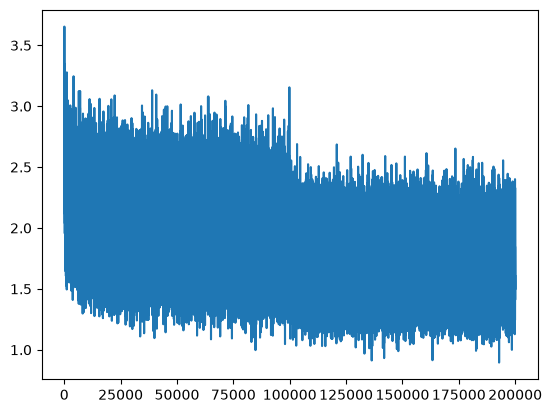

In [27]:
plt.plot(lossi)

unnormalized

(array([3195.,  188.,  152.,  113.,   83.,   64.,   91.,   43.,   56.,
          48.,   51.,   62.,   47.,   37.,   42.,   43.,   45.,   51.,
          40.,   42.,   19.,   35.,   32.,   51.,   83.,   96.,   48.,
          35.,   40.,   31.,   55.,   29.,   28.,   32.,   64.,   43.,
          56.,   46.,   51.,   39.,   63.,   48.,   54.,   66.,   82.,
          91.,   86.,  143.,  235., 3326.]),
 array([-1.  , -0.96, -0.92, -0.88, -0.84, -0.8 , -0.76, -0.72, -0.68,
        -0.64, -0.6 , -0.56, -0.52, -0.48, -0.44, -0.4 , -0.36, -0.32,
        -0.28, -0.24, -0.2 , -0.16, -0.12, -0.08, -0.04,  0.  ,  0.04,
         0.08,  0.12,  0.16,  0.2 ,  0.24,  0.28,  0.32,  0.36,  0.4 ,
         0.44,  0.48,  0.52,  0.56,  0.6 ,  0.64,  0.68,  0.72,  0.76,
         0.8 ,  0.84,  0.88,  0.92,  0.96,  1.  ]),
 <BarContainer object of 50 artists>)

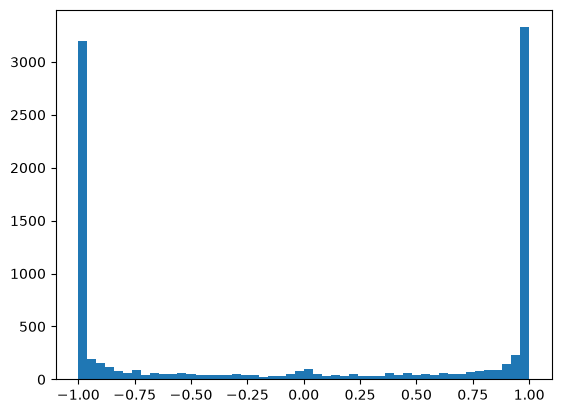

In [32]:
plt.hist(layer.view(-1).tolist(), 50)

tanh(h) = -/+ 1 ------> dtanh/dh = 1 - tanh(h)^2 = 0. AKA vanishing gradients

(array([1.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 1.000e+00,
        1.000e+00, 1.000e+00, 4.000e+00, 3.000e+00, 7.000e+00, 1.500e+01,
        1.700e+01, 2.700e+01, 3.700e+01, 5.800e+01, 8.800e+01, 1.130e+02,
        1.410e+02, 2.210e+02, 2.900e+02, 3.250e+02, 4.280e+02, 4.760e+02,
        5.080e+02, 5.630e+02, 7.200e+02, 1.044e+03, 8.130e+02, 6.810e+02,
        5.220e+02, 5.970e+02, 4.780e+02, 3.570e+02, 2.780e+02, 2.280e+02,
        1.430e+02, 1.280e+02, 7.800e+01, 6.300e+01, 4.400e+01, 2.900e+01,
        1.700e+01, 2.000e+01, 1.200e+01, 9.000e+00, 8.000e+00, 3.000e+00,
        2.000e+00, 1.000e+00]),
 array([-28.43090248, -27.40269344, -26.37448441, -25.34627537,
        -24.31806633, -23.28985729, -22.26164825, -21.23343922,
        -20.20523018, -19.17702114, -18.1488121 , -17.12060307,
        -16.09239403, -15.06418499, -14.03597595, -13.00776691,
        -11.97955788, -10.95134884,  -9.9231398 ,  -8.89493076,
         -7.86672173,  -6.83851269,  -5.81030365,  -4.78

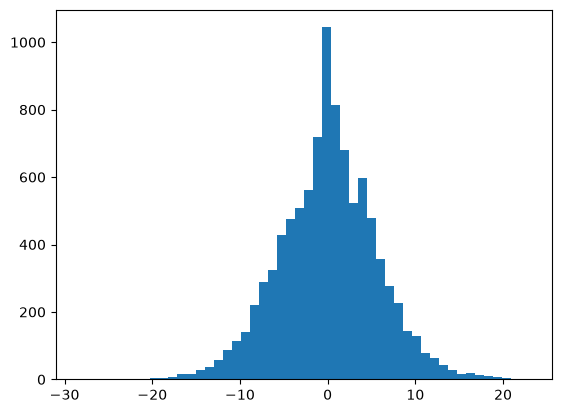

In [33]:
plt.hist(h.view(-1).tolist(), 50)

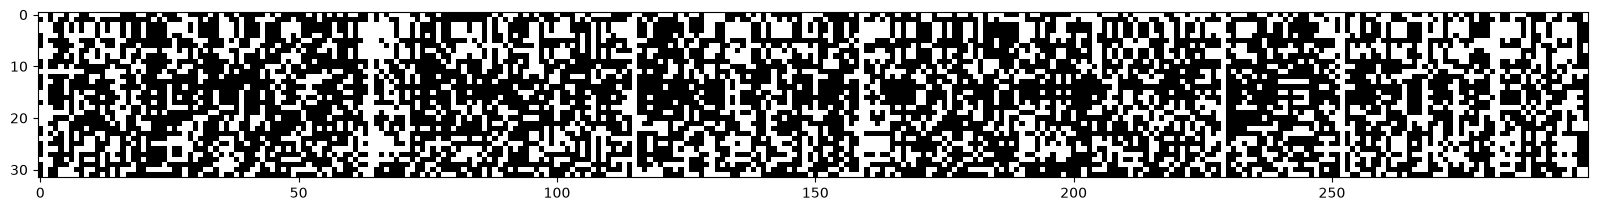

In [41]:
# black is dead neuron, brain damage
plt.figure(figsize=(20, 10))
plt.imshow(layer.abs() < 0.99, cmap="gray", interpolation="nearest")

normalized initialization (Kaiming init)

- https://arxiv.org/pdf/1502.01852
- https://docs.pytorch.org/docs/2.14/nn.init.html#torch.nn.init.kaiming_normal_

BatchNorm
(normalize every minibatch), backprop is now coupled across batch -- increases jitter inside
- https://arxiv.org/pdf/1502.03167

In [11]:
nvec = 10
EMB = torch.randn(27, nvec)
nin = nvec * blocks
W1 = torch.randn((nin,200)) * (5/3) / nin**0.5 # Kaiming Init
b1 = torch.randn(200) * 0.01
W2 = torch.randn((200,27)) * 0.01
b2 = torch.randn(27) * 0.1

# batch norm adjust
gamma, beta = torch.ones((1,200)), torch.zeros((1,200))

params = [EMB, W1, b1, W2, b2, gamma, beta]

for p in params:
	p.requires_grad = True
lossi = []
for i in range(100000):
	ixs = torch.randint(0, Xtrain.shape[0], (32,))
	ctx, target = Xtrain[ixs], Ytrain[ixs]
	emb = EMB[ctx]
	h = emb.view(-1, nin) @ W1 + b1

	# BATCHNORM
	h = (h - h.mean(0,keepdim=True)) / h.std(0,keepdim=True)
	h = gamma * h + beta

	layer = torch.tanh(h)
	logits = layer @ W2 + b2
	loss = F.cross_entropy(logits, target)
	for p in params:
		p.grad = None
	loss.backward()
	lr = 0.1 if i < 100000 else 0.01
	with torch.no_grad():
		for p in params:
			p -= lr * p.grad
	lossi.append(loss.item())
print(loss.item())

1.6047743558883667


batchnorm running

In [13]:
nvec = 10
EMB = torch.randn(27, nvec)
nin = nvec * blocks
nhidden = 200
W1 = torch.randn((nin,nhidden)) * (5/3) / nin**0.5
# REDUNDANT
# b1 = torch.randn(nhidden) * 0.01
W2 = torch.randn((nhidden,27)) * 0.01
b2 = torch.randn(27) * 0.1


# batch norm adjust
gamma, beta = torch.ones((1,nhidden)), torch.zeros((1,nhidden))

params = [EMB, W1, W2, b2, gamma, beta]

for p in params:
	p.requires_grad = True

lossi = []

# not in params
bnsrunning, bnmrunning = torch.ones((1,nhidden)), torch.zeros((1,nhidden))

for i in range(100000):
	ixs = torch.randint(0, Xtrain.shape[0], (32,))
	ctx, target = Xtrain[ixs], Ytrain[ixs]
	emb = EMB[ctx]
	h = emb.view(-1, nin) @ W1

	# BATCHNORM running
	bnmi, bnsi = h.mean(0,keepdim=True), h.std(0,keepdim=True)
	
	# collect the bns
	with torch.no_grad():
		bnmrunning = 0.99 * bnmrunning + 0.01 * bnmi
		bnsrunning = 0.99 * bnsrunning + 0.01 * bnsi

	h = (h - bnmi) / bnsi
	h = gamma * h + beta


	layer = torch.tanh(h)
	logits = layer @ W2 + b2
	loss = F.cross_entropy(logits, target)
	for p in params:
		p.grad = None
	loss.backward()
	lr = 0.1 if i < 100000 else 0.01
	with torch.no_grad():
		for p in params:
			p -= lr * p.grad
	lossi.append(loss.item())
	# break

print(loss.item())

1.8477411270141602


LOSS with batchnorm

In [14]:
@torch.no_grad()
def get_loss(split):
	X, Y = {
		"train": (Xtrain, Ytrain),
		"val": (Xval, Yval)
	}[split]

	emb = EMB[X]
	h = emb.view(-1, nin) @ W1 + b1

	# BATCHNORM
	h = (h - bnmrunning) / bnsrunning
	h = gamma * h + beta

	layer = torch.tanh(h)
	logits = layer @ W2 + b2
	loss = F.cross_entropy(logits, Y)

	print(split, loss.item())

get_loss("train")
get_loss("val")


train 1.7677727937698364
val 2.6440963745117188


In [16]:
# gen names
alpha = "abcdefghijklmnopqrstuvwxyz."

for i in range(20):
	ctx = [0] * blocks
	name = ""
	k = 0

	while k < 20:
		emb = EMB[ctx]

		layer = torch.tanh(emb.view(-1, nin) @ W1)
		logits = layer @ W2 + b2

		probs = torch.softmax(logits, axis=1)

		cidx = torch.multinomial(probs, num_samples=1, replacement=True).item()
		c = alpha[cidx]
		name += c

		if c == ".":
			break

		ctx = ctx[1:] + [cidx]
		k += 1

	print(name)

joscer.
ritzrlaiklerdentndth
mvkanavhye.
gwa.
pfebless.
mbah.
gimdentzlegnoxiqtt.
flvul.
shtth.
jpa.
jpandth.
xutusshdrbeth.
gise.
gisqy.
phvoa.
xpyntzl.
sh.
jampbol.
pficalmarblen.
shrrigh.


entropy of initial letter.

<BarContainer object of 27 artists>

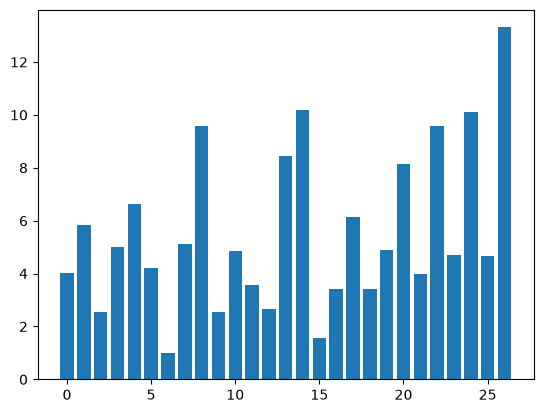

In [29]:
emb = EMB[[0,0,0]]
layer = torch.tanh(emb.view(-1, nin) @ W1)
logits = layer @ W2 + b2
probs = -torch.softmax(logits, axis=1).log()
plt.bar(range(probs.shape[1]), probs[0].detach().numpy())